In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [2]:
df = pd.read_csv("Mall_Customers.csv")

df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df.shape

(200, 5)

In [4]:
df.describe

<bound method NDFrame.describe of      CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0             1    Male   19                  15                      39
1             2    Male   21                  15                      81
2             3  Female   20                  16                       6
3             4  Female   23                  16                      77
4             5  Female   31                  17                      40
..          ...     ...  ...                 ...                     ...
195         196  Female   35                 120                      79
196         197  Female   45                 126                      28
197         198    Male   32                 126                      74
198         199    Male   32                 137                      18
199         200    Male   30                 137                      83

[200 rows x 5 columns]>

In [5]:
df.isnull().sum()

CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [8]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [9]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 200
Number of columns: 5


In [10]:
df["Genre"].value_counts()

Genre
Female    112
Male       88
Name: count, dtype: int64

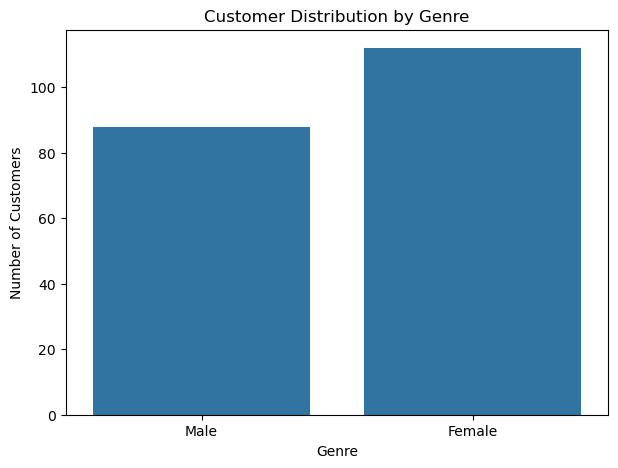

In [11]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x="Genre")

plt.title("Customer Distribution by Genre")
plt.xlabel("Genre")
plt.ylabel("Number of Customers")

plt.show()

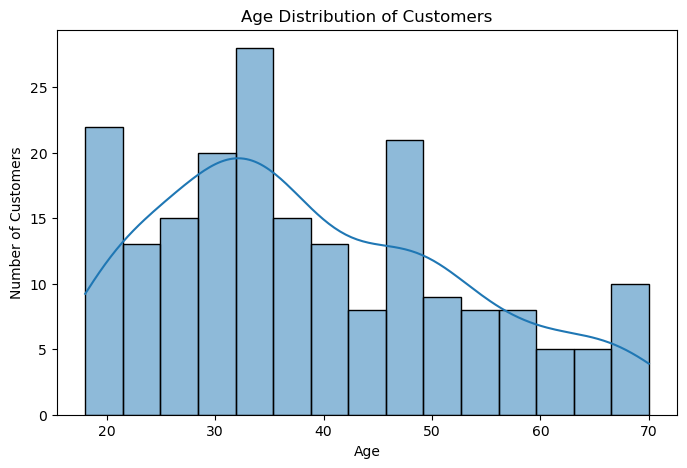

In [12]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="Age",
    bins=15,
    kde=True
)

plt.title("Age Distribution of Customers")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

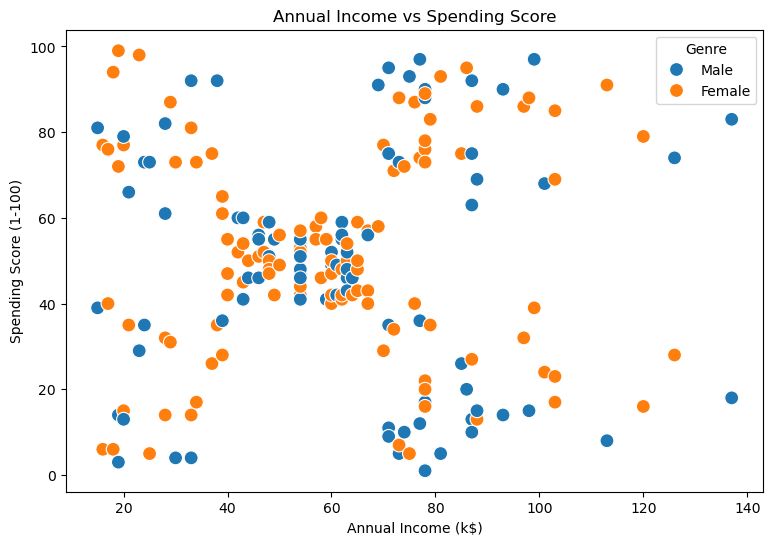

In [13]:
plt.figure(figsize=(9,6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Genre",
    s=100
)

plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")

plt.show()

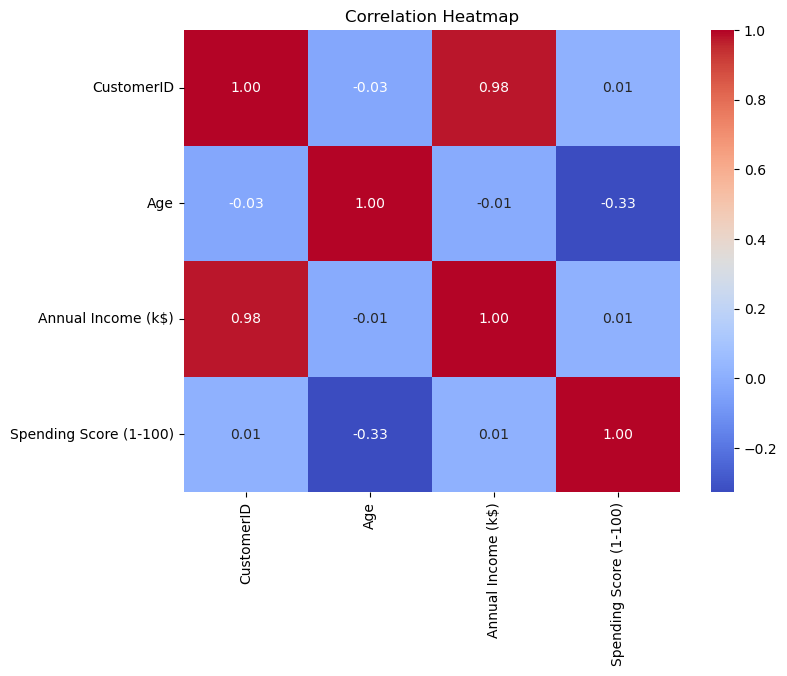

In [14]:
plt.figure(figsize=(8,6))

numeric_df = df.select_dtypes(include=np.number)

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [15]:
df_clean = df.drop("CustomerID", axis=1)

In [16]:
features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

X = df_clean[features]

In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [18]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

In [20]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

inertia = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

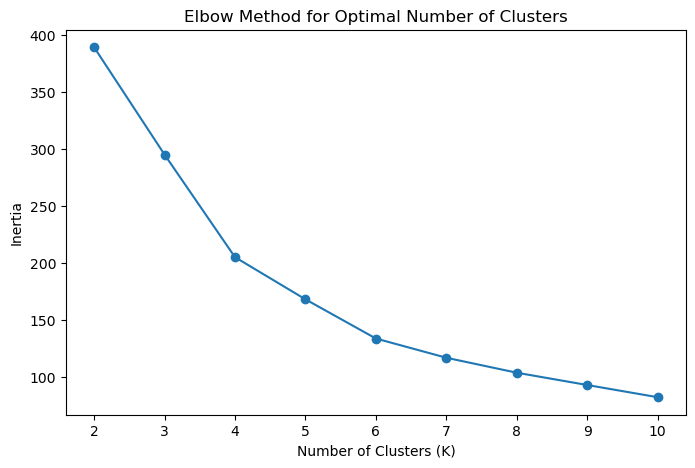

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), inertia, marker="o")

plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(range(2, 11))

plt.show()

In [22]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

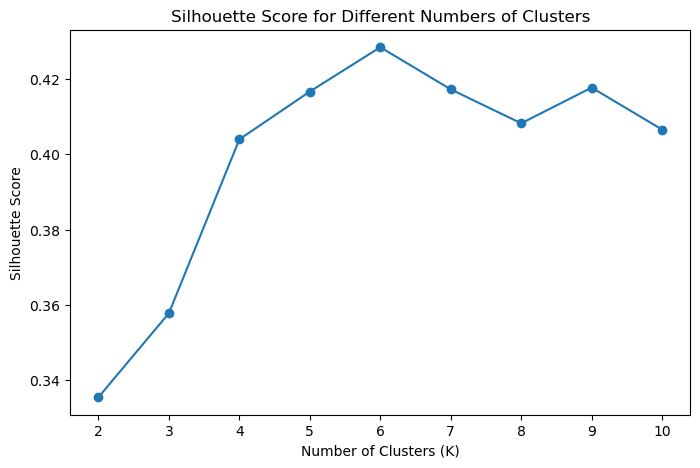

In [23]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o"
)

plt.title("Silhouette Score for Different Numbers of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))

plt.show()

In [24]:
best_k = range(2, 11)[np.argmax(silhouette_scores)]

print("Best K according to Silhouette Score:", best_k)
print("Best Silhouette Score:", max(silhouette_scores))

Best K according to Silhouette Score: 6
Best Silhouette Score: 0.4284167762892593


In [25]:
kmeans_final = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans_final.fit_predict(X_scaled)

print(df.head())

   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   19                  15                      39   
1           2    Male   21                  15                      81   
2           3  Female   20                  16                       6   
3           4  Female   23                  16                      77   
4           5  Female   31                  17                      40   

   Cluster  
0        4  
1        4  
2        5  
3        4  
4        5  


In [26]:
cluster_counts = df["Cluster"].value_counts().sort_index()

print(cluster_counts)

Cluster
0    45
1    39
2    33
3    39
4    23
5    21
Name: count, dtype: int64


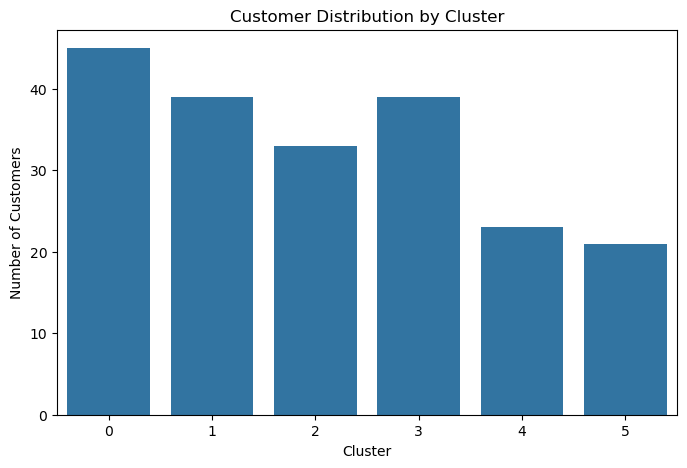

In [27]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Cluster")

plt.title("Customer Distribution by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")

plt.show()

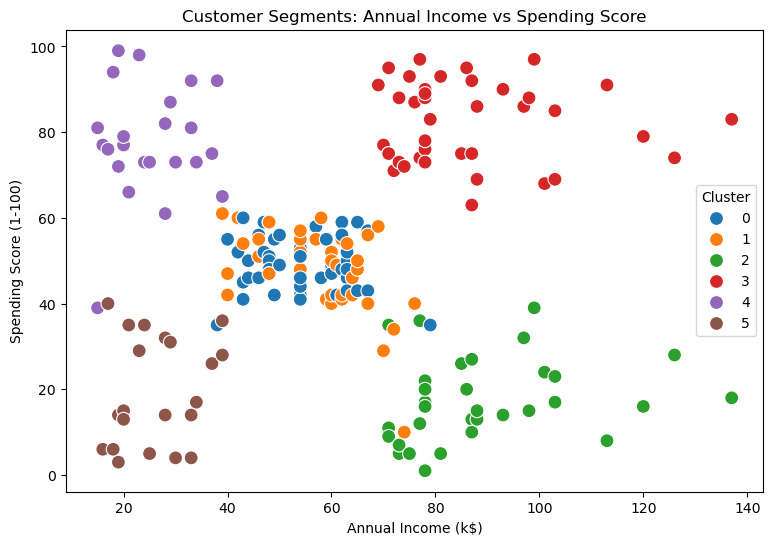

In [28]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="tab10",
    s=100
)

plt.title("Customer Segments: Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")

plt.show()

In [29]:
cluster_summary = df.groupby("Cluster")[
    ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
].mean().round(2)

cluster_summary

,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,56.33,54.27,49.07
1,26.79,57.10,48.13
2,41.94,88.94,16.97
3,32.69,86.54,82.13
4,25.00,25.26,77.61
5,45.52,26.29,19.38


| Cluster | Customer Profile                   | Interpretation                                                   |
| ------- | ---------------------------------- | ---------------------------------------------------------------- |
| **0**   | Age ~56, Income ~54k, Spending ~49 | Older customers with **moderate income and moderate spending**   |
| **1**   | Age ~27, Income ~57k, Spending ~48 | Younger customers with **moderate income and moderate spending** |
| **2**   | Age ~42, Income ~89k, Spending ~17 | **High-income but low-spending** customers                       |
| **3**   | Age ~33, Income ~87k, Spending ~82 | **High-income and high-spending** customers                      |
| **4**   | Age ~25, Income ~25k, Spending ~78 | **Low-income but high-spending** younger customers               |
| **5**   | Age ~46, Income ~26k, Spending ~19 | **Low-income and low-spending** customers                        |


In [30]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

pca_df["Cluster"] = df["Cluster"]

pca_df.head()

,PC1,PC2,Cluster
0,-0.615720,-1.763481,4
1,-1.665793,-1.820747,4
2,0.337862,-1.674799,5
3,-1.456573,-1.772430,4
4,-0.038465,-1.662740,5


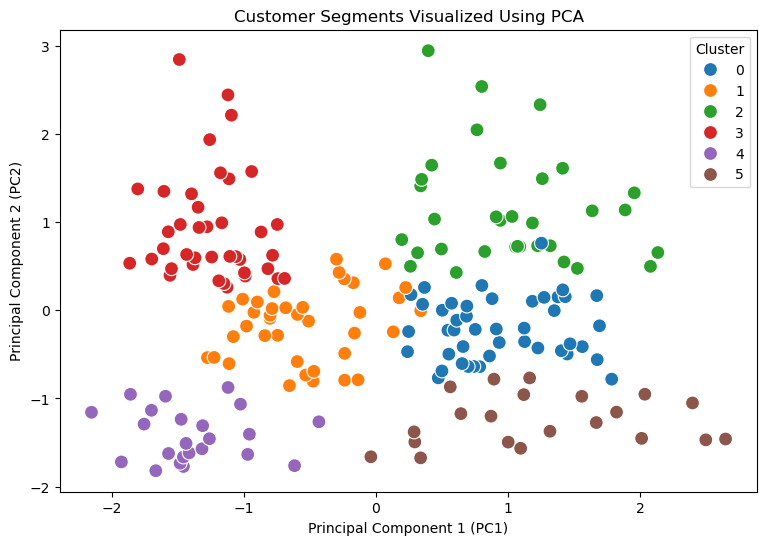

In [31]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    s=100
)

plt.title("Customer Segments Visualized Using PCA")
plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")
plt.legend(title="Cluster")

plt.show()

In [32]:
genre_cluster = pd.crosstab(
    df["Cluster"],
    df["Genre"]
)

genre_cluster

Genre,Female,Male
Cluster,,
0,26,19
1,25,14
2,14,19
3,21,18
4,13,10
5,13,8


In [33]:
cluster_summary = df.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

cluster_summary

,Customer_Count,Average_Age,Average_Income,Average_Spending_Score
Cluster,,,,
0,45,56.33,54.27,49.07
1,39,26.79,57.10,48.13
2,33,41.94,88.94,16.97
3,39,32.69,86.54,82.13
4,23,25.00,25.26,77.61
5,21,45.52,26.29,19.38


| Cluster | Segment Description                                   | Business Approach                                                                 |
| ------- | ----------------------------------------------------- | --------------------------------------------------------------------------------- |
| **0**   | Older customers, moderate income, moderate spending   | Loyalty programs, personalized offers, retention campaigns                        |
| **1**   | Younger customers, moderate income, moderate spending | Engagement campaigns, targeted promotions, personalized recommendations           |
| **2**   | Higher-income customers with low spending             | Premium offers, personalized incentives, understand barriers to purchase          |
| **3**   | Higher-income customers with high spending            | Premium products, loyalty rewards, cross-selling and personalized recommendations |
| **4**   | Younger customers with lower income but high spending | Affordable promotions, discounts, engagement campaigns                            |
| **5**   | Older customers with lower income and low spending    | Value-based offers, retention strategies, low-cost promotions                     |


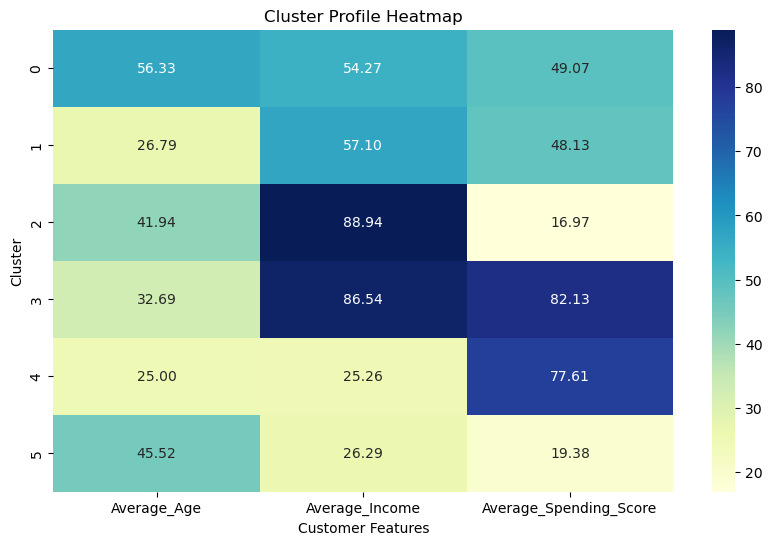

In [34]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    cluster_summary[
        ["Average_Age", "Average_Income", "Average_Spending_Score"]
    ],
    annot=True,
    fmt=".2f",
    cmap="YlGnBu"
)

plt.title("Cluster Profile Heatmap")
plt.xlabel("Customer Features")
plt.ylabel("Cluster")

plt.show()

### Business Insights and Customer Segment Interpretation

The K-Means clustering analysis divided the 200 customers into six distinct segments based on age, annual income, and spending score.

**Cluster 0 – Older, Moderate-Income, Moderate-Spending Customers**
This cluster contains 45 customers with an average age of 56.33 years, average annual income of 54.27 k$, and average spending score of 49.07. These customers show moderate purchasing behavior. Businesses can focus on loyalty programs, personalized offers, and retention campaigns for this segment.

**Cluster 1 – Young, Moderate-Income, Moderate-Spending Customers**
This cluster contains 39 customers with an average age of 26.79 years, average income of 57.10 k$, and spending score of 48.13. Engagement campaigns, targeted promotions, and personalized product recommendations can be used to encourage stronger customer engagement.

**Cluster 2 – High-Income, Low-Spending Customers**
This cluster contains 33 customers with an average income of 88.94 k$ but a low average spending score of 16.97. These customers have relatively high purchasing capacity but currently show low spending activity. Personalized incentives, premium offers, and campaigns designed to understand their purchasing barriers may help increase engagement.

**Cluster 3 – High-Income, High-Spending Customers**
This cluster contains 39 customers with an average income of 86.54 k$ and a high spending score of 82.13. This segment represents customers with both high income and high spending activity. Businesses can focus on premium products, loyalty rewards, cross-selling, and personalized recommendations.

**Cluster 4 – Young, Low-Income, High-Spending Customers**
This cluster contains 23 customers with an average age of 25 years, average income of 25.26 k$, and a high spending score of 77.61. Affordable promotions, discounts, and engagement-focused campaigns may be useful for this segment.

**Cluster 5 – Older, Low-Income, Low-Spending Customers**
This cluster contains 21 customers with an average age of 45.52 years, average income of 26.29 k$, and a low spending score of 19.38. Value-based offers, affordable products, and retention strategies could be considered for this segment.

### Overall Business Applications

The identified customer segments can support:

* **Targeted marketing:** Different promotional strategies can be designed for different customer groups.
* **Customer retention:** Low-spending segments can be targeted with suitable engagement and retention campaigns.
* **Personalized recommendations:** High-income and high-spending customers can receive more personalized product recommendations.
* **Promotional planning:** Discounts and affordable offers can be targeted toward customers who may be more price-sensitive.
* **Customer engagement:** Younger and moderate-spending customers can be targeted with campaigns designed to increase engagement.

These recommendations are potential applications of the observed customer profiles and would need to be evaluated using actual campaign and customer-response data.
